# Assessment Notebook

In [1]:
# Package for handling numerical arrays
import numpy as np

# Package for statistical functions
import scipy.stats as stats

# Package for handling dataframes
import pandas as pd

#  Packages for plotting
import matplotlib.pyplot as plt

## Problem 1: Exploring Petal Length

Problem 1 investigates the distribution of petal length measurements for all 150 flowers in the Iris dataset, as well as the distributions for each individual species. The analysis includes plotting histograms, superimposing normal distribution curves using the calculated mean and standard deviation, and comparing the observed distributions with the theoretical normal distributions.

### Prepare data

In [2]:
# Load the iris dataset from seaborn's GitHub repository
iris = pd.read_csv('https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv')

# Display the first few rows of the dataset
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
# Extract the petal length column
petal_length = iris['petal_length']

# Show first 5 values of petal length
petal_length[0:5]

0    1.4
1    1.4
2    1.3
3    1.5
4    1.4
Name: petal_length, dtype: float64

### Mean and standard deviation

To fit a normal distribution to the data, we need: 
- `Mean`: represents the centre of the normal distribution.
- `Standard deviation`: measures the spread of the distribution around the mean.

In [4]:
# Mean of petal length
mean = petal_length.mean()

# Show
print('Mean of petal length:', mean)

Mean of petal length: 3.7580000000000005


In [5]:
# Standard deviation of petal length
st_dev = petal_length.std()

# Show
print('Standard deviation of petal length:', st_dev)

Standard deviation of petal length: 1.7652982332594662


### Overall Petal Length Distribution 

To superimpose normal distribution on the existing histogram, the [Real Python](https://realpython.com/numpy-random-normal/#specify-the-mean-and-standard-deviation) article was used as a guide for the approach.

Text(0, 0.5, 'Probability Density')

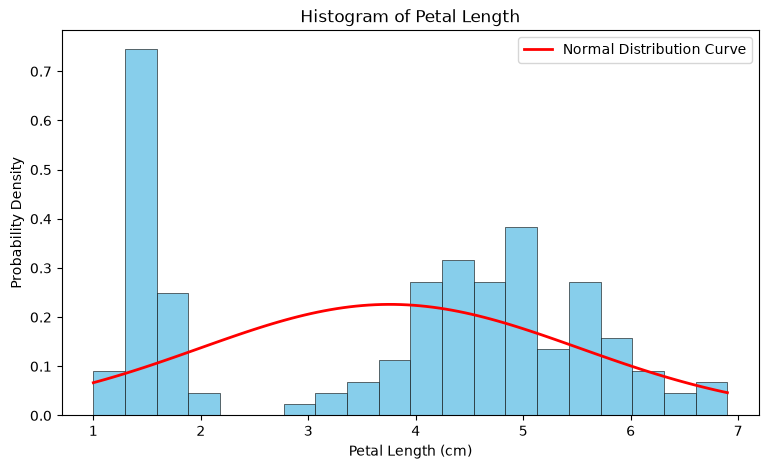

In [6]:
# Create figure for histogram
plt.figure(figsize=(9, 5))

# Petal length histogram
plt.hist(petal_length, bins=20, density=True, color='skyblue', edgecolor='black', linewidth=0.4)

# Generate x values for the normal distribution curve
x = np.linspace(petal_length.min(), petal_length.max(), 100)

# Generate y values for the normal distribution curve
y = stats.norm.pdf(x, loc=mean, scale=st_dev)

# Plot the normal distribution curve
plt.plot(x, y, color='red', linewidth=2, label='Normal Distribution Curve')

# Add title and labels
plt.title('Histogram of Petal Length')

# Add legend
plt.legend()

# Add x label
plt.xlabel('Petal Length (cm)')

# Add y label
plt.ylabel('Probability Density')

### Species_Specific Mean and Standard Deviation

A quick way to compute `mean` and `standard deviation` for each species is to use Pandas' `.groupby()` method. This method groups the dataset by a specified column, allowing us to apply aggregate functions such as `mean()` and `std()` to each group separately. See the official [documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html).

In [7]:
# Group by species and calculate mean and standard deviation of petal length
species_statistics = iris.groupby('species')['petal_length'].agg(['mean', 'std'])

# Display the statistics
print(species_statistics)

             mean       std
species                    
setosa      1.462  0.173664
versicolor  4.260  0.469911
virginica   5.552  0.551895


### Species-Specific Distributions

To investigate the distribution of petal length within each species, separate histograms are created for Setosa, Versicolor and Virginica.

A reusable function is defined to generate each histogram and superimpose a normal distribution. This avoids repeating the same plotting code for each species and ensures a consistent approach across all three plots.

In [8]:
# Define a function to plot histogram of petal lengths 
# with superimposed normal distribution for each species

def plot_species_histogram(data, species, color):
    # Calculate mean 
    mean = data.mean()
    # Calculate standard deviation 
    st_dev = data.std()

    # Create histogram using probability density
    plt.hist(data, bins=10, density=True, color=color, edgecolor='black', linewidth=0.4)

    # Generate x values for normal distribution
    x = np.linspace(data.min(), data.max(), 200)

    # Calculate normal probability density 
    y = stats.norm.pdf(x, loc=mean, scale=st_dev)

    # Superimpose normal distribution 
    plt.plot(x, y, color='red', linewidth=2, label='Normal Distribution')

    # Add title and labels
    plt.title(f'Histogram of Petal Length for {species}')

    # Add x label
    plt.xlabel('Petal Length (cm)')

    # Add y label
    plt.ylabel('Probability Density')

    # Add legend
    plt.legend()

    # Show the plot
    plt.show()

### Setosa Petal Length histogram

In [9]:
# Extract petal lengths for the species setosa
petal_length_setosa = iris[iris['species'] == 'setosa']['petal_length']

# Show first 2 values of petal length for setosa
petal_length_setosa[0:2]

0    1.4
1    1.4
Name: petal_length, dtype: float64

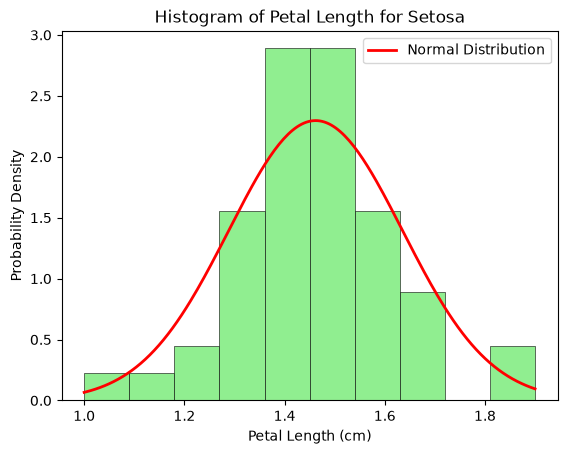

In [10]:
# Call the function to plot histogram for setosa
plot_species_histogram(petal_length_setosa, 'Setosa', 'lightgreen')

### Versicolor Petal Length histogram

In [11]:
# Extract petal lengths for the species versicolor
petal_length_versicolor = iris[iris['species'] == 'versicolor']['petal_length']

# Show first 2 values of petal length for versicolor
petal_length_versicolor[0:2]

50    4.7
51    4.5
Name: petal_length, dtype: float64

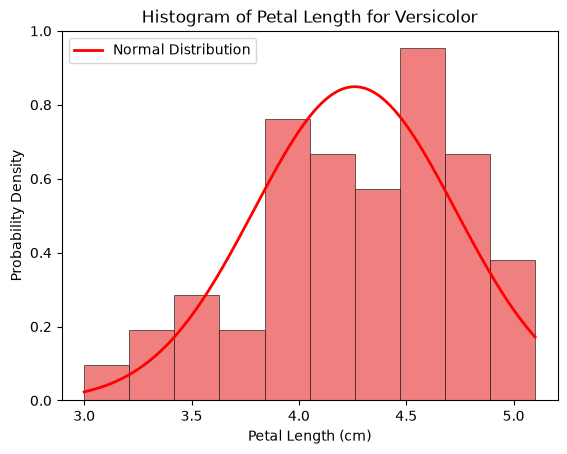

In [12]:
# Call the function to plot histogram for versicolor
plot_species_histogram(petal_length_versicolor, 'Versicolor', 'lightcoral')

### Virginica Petal Length histogram

In [13]:
# Extract petal lengths for the species virginica
petal_length_virginica = iris[iris['species'] == 'virginica']['petal_length']

# Show first 2 values of petal length for virginica
petal_length_virginica[0:2]

100    6.0
101    5.1
Name: petal_length, dtype: float64

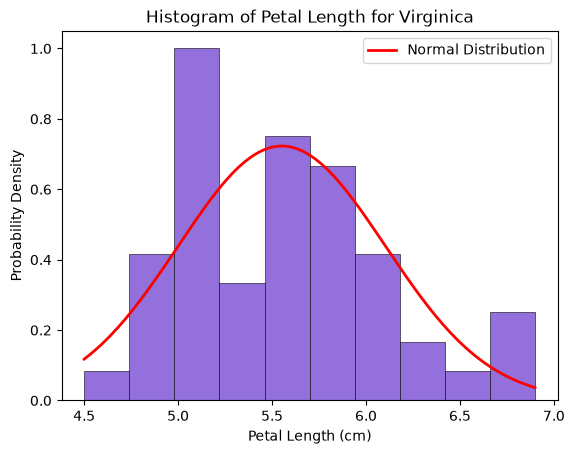

In [14]:
# Call the function to plot histogram for virginica
plot_species_histogram(petal_length_virginica, 'Virginica', 'mediumpurple')

## Problem 2: Correlation Between Petal Length and Petal Width

Problem 2 involves ..

## Problem 3: Comparing Species Using t-Tests

Problem 3 involves ..

## Problem 4: Comparing the Species Using ANOVA

Problem 4 involves ..

## End